# Copper Price Forecasting Using the Díaz et al. (2020) Approach

**Paper:** Díaz, J. D., Hansen, E., & Cabrera, G. (2020). “A random walk through the trees: Forecasting copper prices using decision learning methods.” *Resources Policy*, 69, 101859. https://doi.org/10.1016/j.resourpol.2020.101859

## What this notebook does
- Uses your eight Investing.com daily CSVs: copper, gold, silver, WTI crude oil, natural gas, lean hogs, coffee, and the Dow Jones Industrial Average.
- Joins the series by common trading dates.
- Uses lagged market prices as predictors to avoid look-ahead leakage.
- Compares a random-walk benchmark, a regression tree, Random Forest, and Gradient Boosting Regression Trees (GBRT).
- Uses a chronological train/test split and reports MAE, RMSE, and R².

## Important data note
These replacement files are **much better** than the earlier uploads: they contain thousands of observations each, with dates beginning around **January 2010** and running through **October 2026**. However, the paper's study period begins in January 2008 and ends in May 2020. Your files do not reach back to 2008, so this notebook defaults to **January 13, 2010–May 31, 2020** for a closer comparison with the paper's end date. You can change `END_DATE` to use newer data, but that would no longer match the paper's historical period.

This is a close classroom implementation of the paper's broad design, **not an exact replication** of all the paper's forecast horizons, split dates, and hyperparameter settings. The exact Investing.com futures series may also differ from the original paper's market data.

## Additional paper-style tables
The final section generates Table 1 descriptive statistics/correlations and two out-of-sample forecasting tables organized by forecast horizon and lag length. These are recalculated from your own CSVs; they will not exactly match the paper because your series begin in 2010 and are Investing.com futures data.

## 1. Import libraries and set the sample period

In [23]:
import warnings
warnings.filterwarnings("ignore")

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42

# To approximate the paper's historical end date, use data through May 2020.
# Your uploaded files start in January 2010, so the beginning cannot match the paper's 2008 start.
START_DATE = "2010-01-01"
END_DATE = "2020-05-31"

FILES = {
    "Copper": "Copper Futures Historical Data.csv",
    "Gold": "Gold Futures Historical Data.csv",
    "Silver": "Silver Futures Historical Data.csv",
    "CrudeOil": "Crude Oil WTI Futures Historical Data.csv",
    "NaturalGas": "Natural Gas Futures Historical Data.csv",
    "LeanHogs": "Lean Hogs Futures Historical Data.csv",
    "Coffee": "US Coffee C Futures Historical Data.csv",
    "DowJones": "Dow Jones Industrial Average Historical Data.csv",
}

PREDICTORS = ["Copper", "Gold", "Silver", "CrudeOil", "NaturalGas",
              "LeanHogs", "Coffee", "DowJones"]

## 2. Load and clean the eight uploaded datasets

In [24]:
def parse_price(series):
    # Investing.com exports generally use commas as thousands separators.
    return pd.to_numeric(
        series.astype(str).str.replace(",", "", regex=False).str.replace("%", "", regex=False),
        errors="coerce"
    )

series_list = []
source_summary = []

for variable, filename in FILES.items():
    if not os.path.exists(filename):
        raise FileNotFoundError(
            f"Cannot find {filename!r}. Put all eight CSV files in the same folder as this notebook."
        )

    temp = pd.read_csv(filename)
    if not {"Date", "Price"}.issubset(temp.columns):
        raise ValueError(f"{filename} needs columns named 'Date' and 'Price'.")

    temp["Date"] = pd.to_datetime(temp["Date"], errors="coerce")
    temp[variable] = parse_price(temp["Price"])
    temp = temp[["Date", variable]].dropna().drop_duplicates(subset="Date")
    temp = temp.sort_values("Date")
    source_summary.append({
        "Series": variable,
        "Rows": len(temp),
        "First date": temp["Date"].min().date(),
        "Last date": temp["Date"].max().date()
    })
    series_list.append(temp)

# Inner join keeps only dates present in all eight files.
data = series_list[0]
for temp in series_list[1:]:
    data = data.merge(temp, on="Date", how="inner")

data = data.sort_values("Date").dropna().reset_index(drop=True)
data = data[(data["Date"] >= START_DATE) & (data["Date"] <= END_DATE)].reset_index(drop=True)

display(pd.DataFrame(source_summary))
print(f"Common observations in selected period: {len(data):,}")
print(f"Common date range: {data['Date'].min().date()} to {data['Date'].max().date()}")
display(data.head())
display(data.tail())

,Series,Rows,First date,Last date
0,Copper,4321,2010-01-13,2026-10-13
1,Gold,3899,2010-01-13,2026-10-13
2,Silver,3813,2010-01-13,2026-10-13
3,CrudeOil,4362,2010-01-13,2026-10-13
4,NaturalGas,4365,2010-01-13,2026-10-13
5,LeanHogs,4240,2010-01-13,2026-10-13
6,Coffee,4234,2010-01-13,2026-10-13
7,DowJones,4495,2010-01-13,2026-10-13


Common observations in selected period: 2,386
Common date range: 2010-01-13 to 2020-05-28


,Date,Copper,Gold,Silver,CrudeOil,NaturalGas,LeanHogs,Coffee,DowJones
0,2010-01-13,3.4000,1136.8,18.550,79.65,5.733,68.97,145.15,10680.77
1,2010-01-14,3.3875,1143.0,18.655,79.39,5.588,69.05,144.35,10710.55
2,2010-01-15,3.3660,1130.5,18.427,78.00,5.691,69.97,140.75,10609.65
3,2010-01-20,3.3550,1112.6,17.880,77.62,5.496,70.45,139.20,10603.15
4,2010-01-21,3.2950,1103.2,17.510,76.08,5.615,70.80,138.70,10389.88


,Date,Copper,Gold,Silver,CrudeOil,NaturalGas,LeanHogs,Coffee,DowJones
2381,2020-05-20,2.4600,1752.1,18.031,33.94,1.909,56.88,105.65,24575.90
2382,2020-05-21,2.4320,1721.9,17.364,34.34,1.852,59.35,104.75,24474.12
2383,2020-05-26,2.4185,1705.6,17.595,34.77,1.945,60.50,105.10,24995.11
2384,2020-05-27,2.3820,1726.8,17.757,33.23,1.886,60.17,102.50,25548.27
2385,2020-05-28,2.4215,1728.3,18.009,34.06,1.919,56.92,99.10,25400.64


## 3. Plot the copper price and standardized predictors

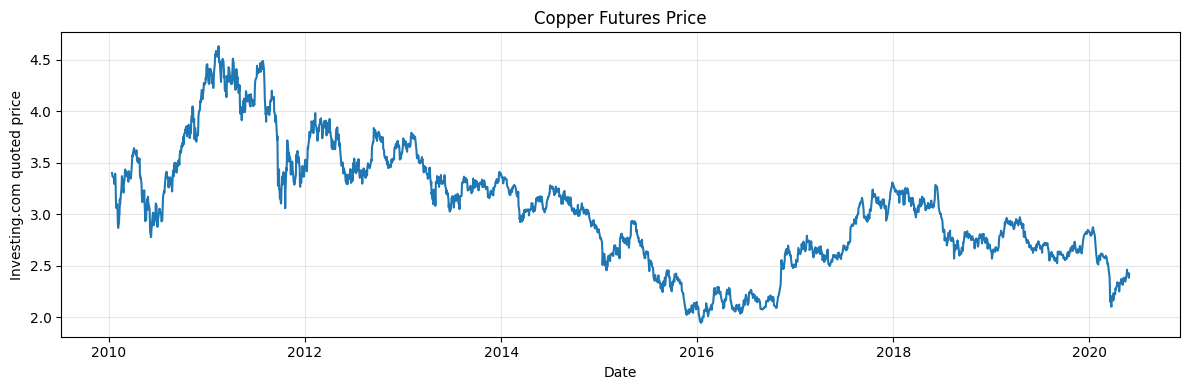

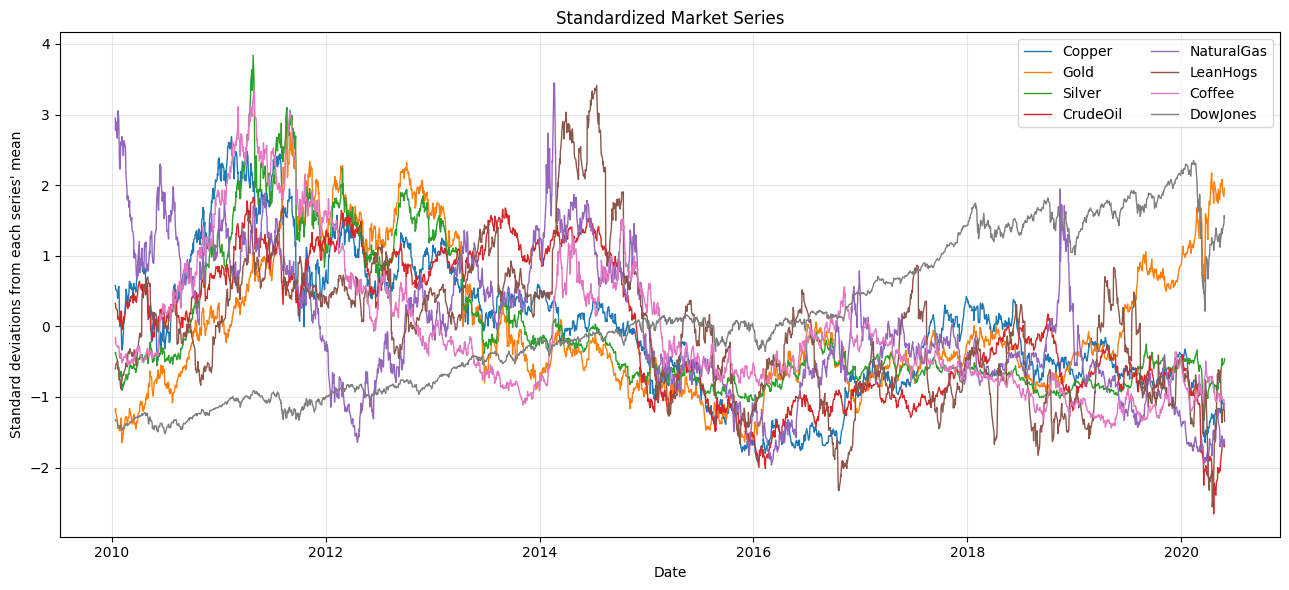

In [25]:
plt.figure(figsize=(12, 4))
plt.plot(data["Date"], data["Copper"])
plt.title("Copper Futures Price")
plt.xlabel("Date")
plt.ylabel("Investing.com quoted price")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# The predictors have different units; standardize only for this visualization.
std_data = data[PREDICTORS].apply(
    lambda col: (col - col.mean()) / col.std(ddof=0)
)
plt.figure(figsize=(13, 6))
for col in std_data.columns:
    plt.plot(data["Date"], std_data[col], label=col, linewidth=1)
plt.title("Standardized Market Series")
plt.xlabel("Date")
plt.ylabel("Standard deviations from each series' mean")
plt.legend(ncol=2)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Build lagged features

The model predicts copper's price at time *t* using market prices from the prior observation (*t−1*). For this notebook, each of the eight series contributes a one-observation lag. This avoids using same-day predictor values that may not have been available when the forecast was made.

The paper evaluates multiple forecast horizons; this notebook implements a one-observation-ahead setup as a reproducible baseline. It does not claim to reproduce every horizon in the paper.

In [26]:
model_data = data[["Date"] + PREDICTORS].copy()

feature_cols = []
for col in PREDICTORS:
    lag_col = f"{col}_lag1"
    model_data[lag_col] = model_data[col].shift(1)
    feature_cols.append(lag_col)

model_data = model_data.dropna().reset_index(drop=True)
X = model_data[feature_cols]
y = model_data["Copper"]

print("Model observations:", len(model_data))
print("Features:", feature_cols)
display(model_data.head())

Model observations: 2385
Features: ['Copper_lag1', 'Gold_lag1', 'Silver_lag1', 'CrudeOil_lag1', 'NaturalGas_lag1', 'LeanHogs_lag1', 'Coffee_lag1', 'DowJones_lag1']


,Date,Copper,Gold,Silver,CrudeOil,NaturalGas,LeanHogs,Coffee,DowJones,Copper_lag1,Gold_lag1,Silver_lag1,CrudeOil_lag1,NaturalGas_lag1,LeanHogs_lag1,Coffee_lag1,DowJones_lag1
0,2010-01-14,3.3875,1143.0,18.655,79.39,5.588,69.05,144.35,10710.55,3.4000,1136.8,18.550,79.65,5.733,68.97,145.15,10680.77
1,2010-01-15,3.3660,1130.5,18.427,78.00,5.691,69.97,140.75,10609.65,3.3875,1143.0,18.655,79.39,5.588,69.05,144.35,10710.55
2,2010-01-20,3.3550,1112.6,17.880,77.62,5.496,70.45,139.20,10603.15,3.3660,1130.5,18.427,78.00,5.691,69.97,140.75,10609.65
3,2010-01-21,3.2950,1103.2,17.510,76.08,5.615,70.80,138.70,10389.88,3.3550,1112.6,17.880,77.62,5.496,70.45,139.20,10603.15
4,2010-01-22,3.3470,1089.7,16.932,74.54,5.819,69.85,139.60,10172.98,3.2950,1103.2,17.510,76.08,5.615,70.80,138.70,10389.88


## 5. Chronological train/test split

In [27]:
# No shuffling: train on the earlier 80% and evaluate on the later 20%.
split_idx = int(len(model_data) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]
test_dates = model_data["Date"].iloc[split_idx:]

print(f"Training observations: {len(X_train):,}")
print(f"Test observations: {len(X_test):,}")
print(f"Test dates: {test_dates.min().date()} to {test_dates.max().date()}")

Training observations: 1,908
Test observations: 477
Test dates: 2017-12-28 to 2020-05-28


## 6. Fit the tree-based models

In [28]:
# Model families aligned with the paper's overall comparison.
# These are transparent classroom settings, not asserted to be the paper's exact hyperparameters.
models = {
    "Regression Tree": DecisionTreeRegressor(
        max_depth=5, min_samples_leaf=10, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=300, max_depth=8, min_samples_leaf=5,
        max_features=1.0, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting (GBRT)": GradientBoostingRegressor(
        n_estimators=200, learning_rate=0.05, max_depth=2,
        loss="squared_error", random_state=RANDOM_STATE
    ),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"Fitted: {name}")

Fitted: Regression Tree
Fitted: Random Forest
Fitted: Gradient Boosting (GBRT)


## 7. Evaluate forecasts against the random-walk benchmark

In [29]:
# Random-walk forecast: next copper price equals the most recently observed copper price.
predictions = {
    "Random Walk": model_data["Copper_lag1"].iloc[split_idx:].to_numpy()
}
for name, model in models.items():
    predictions[name] = model.predict(X_test)

def calculate_metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted)
    }

results = pd.DataFrame([
    {"Model": name, **calculate_metrics(y_test, pred)}
    for name, pred in predictions.items()
]).sort_values("RMSE").reset_index(drop=True)

display(results.round(4))

,Model,MAE,RMSE,R2
0,Random Walk,0.0277,0.0369,0.9770
1,Gradient Boosting (GBRT),0.0294,0.0383,0.9752
2,Random Forest,0.0293,0.0390,0.9743
3,Regression Tree,0.0334,0.0432,0.9686


## 8. Plot actual copper prices versus model forecasts

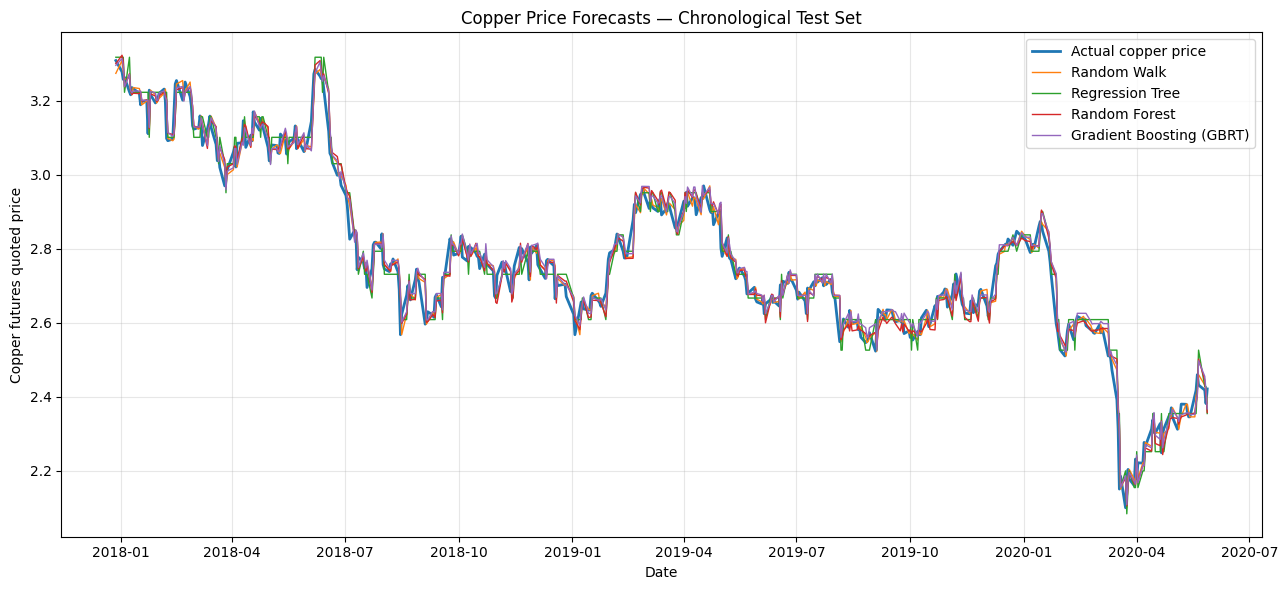

In [30]:
plt.figure(figsize=(13, 6))
plt.plot(test_dates, y_test.to_numpy(), label="Actual copper price", linewidth=2)
for name, pred in predictions.items():
    plt.plot(test_dates, pred, label=name, linewidth=1)
plt.title("Copper Price Forecasts — Chronological Test Set")
plt.xlabel("Date")
plt.ylabel("Copper futures quoted price")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 9. Feature importance

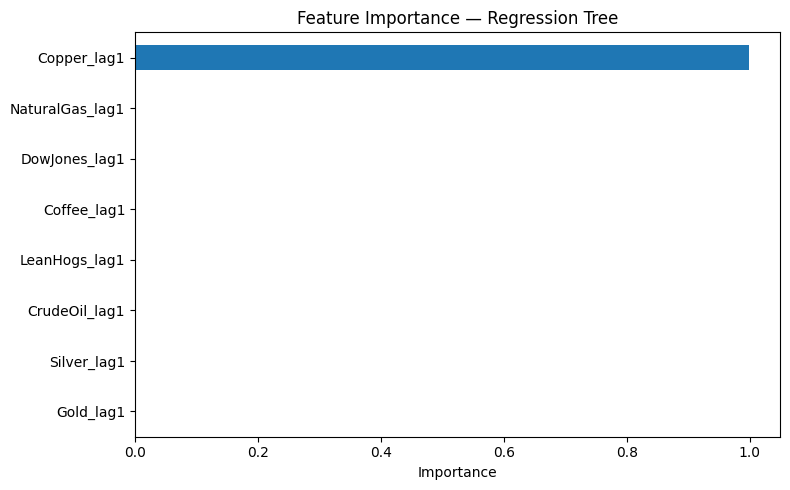

,Importance
Copper_lag1,0.999406
NaturalGas_lag1,0.000569
DowJones_lag1,0.000025
Gold_lag1,0.000000
Silver_lag1,0.000000
CrudeOil_lag1,0.000000
LeanHogs_lag1,0.000000
Coffee_lag1,0.000000


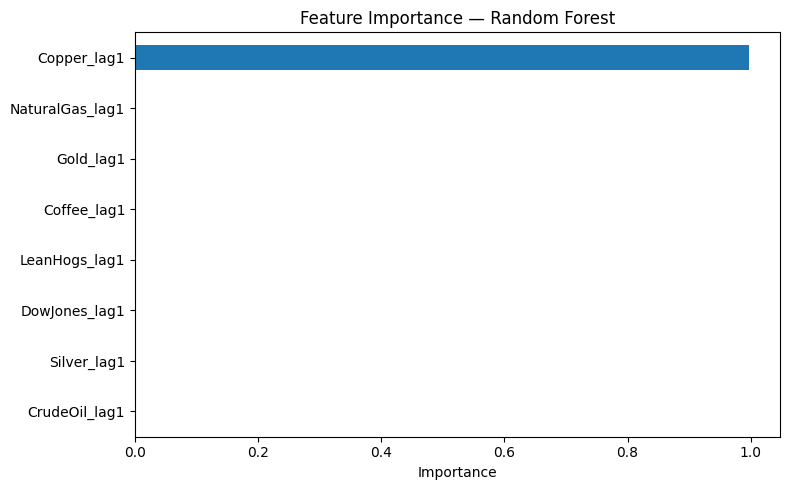

,Importance
Copper_lag1,0.997773
NaturalGas_lag1,0.000551
Gold_lag1,0.000372
Coffee_lag1,0.000308
LeanHogs_lag1,0.000297
DowJones_lag1,0.000259
Silver_lag1,0.000229
CrudeOil_lag1,0.000211


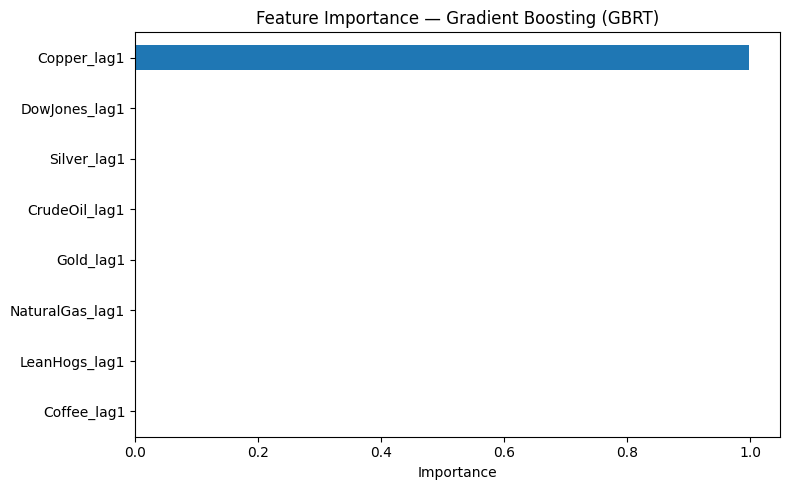

,Importance
Copper_lag1,0.998497
DowJones_lag1,0.000628
Silver_lag1,0.000394
CrudeOil_lag1,0.000202
Gold_lag1,0.000093
NaturalGas_lag1,0.000070
LeanHogs_lag1,0.000066
Coffee_lag1,0.000051


In [31]:
for model_name in ["Regression Tree", "Random Forest", "Gradient Boosting (GBRT)"]:
    model = models[model_name]
    importance = pd.Series(model.feature_importances_, index=feature_cols).sort_values()
    plt.figure(figsize=(8, 5))
    importance.plot(kind="barh")
    plt.title(f"Feature Importance — {model_name}")
    plt.xlabel("Importance")
    plt.tight_layout()
    plt.show()
    display(importance.sort_values(ascending=False).to_frame("Importance"))

## 10. Interpretation and caveats

- **MAE:** average absolute error in the target's quoted price units; lower is better.
- **RMSE:** penalizes larger errors more heavily; lower is better.
- **R²:** can be negative on the test set.
- Compare the models to the random-walk baseline; do not assume a more complex model must perform better.
- The uploaded data now have enough daily observations for a more meaningful experiment than the earlier 22-row files.
- This sample starts in 2010, while the paper starts in 2008. The selected sample ends in May 2020 to align with the paper's end date. Change `END_DATE` to use all available history through 2026, but describe that as an updated-period experiment.
- The paper's exact model settings, forecasting horizons, and evaluation windows should be copied from its full methods section if you need a strict replication. This notebook reproduces the broad design, not every experimental detail.
- Investing.com futures contracts and roll conventions may differ from the original paper's datasets. State this as a data limitation in your report.

### Reference
Díaz, J. D., Hansen, E., & Cabrera, G. (2020). “A random walk through the trees: Forecasting copper prices using decision learning methods.” *Resources Policy*, 69, 101859. https://doi.org/10.1016/j.resourpol.2020.101859

# Tables 1–3: Paper-style descriptive statistics and forecast evaluation

The following cells generate three tables from your uploaded data:
1. **Table 1:** descriptive statistics and correlations.
2. **Table 2-style results:** out-of-sample RMSE and MAE by forecast horizon and number of lags, using a short evaluation window.
3. **Table 3-style results:** the same evaluation design over an extended evaluation window.

**Important:** Your files start in 2010, so the paper's January 2008–October 2011 training period and November 2011–December 2015 short-sample evaluation cannot be reproduced exactly. The code uses available dates and labels the tables as paper-style results, not exact replications. Horizons are approximated as trading observations (1, 5, 21, 126, 252, and 504).

## Table 1. Descriptive statistics and correlations

In [32]:
# Table 1, Panel A: descriptive statistics
table1_panel_a = pd.DataFrame({
    "Mean": data[PREDICTORS].mean(),
    "Std. Dev.": data[PREDICTORS].std(ddof=1),
    "Min": data[PREDICTORS].min(),
    "Max": data[PREDICTORS].max()
}).rename(index={
    "CrudeOil": "Oil", "NaturalGas": "Gas",
    "LeanHogs": "Lean Hogs", "DowJones": "Dow Jones"
}).round(2)

print("Table 1, Panel A: Descriptive Statistics")
display(table1_panel_a)

# Panel B: Pearson correlations with p < 0.05 marked by *
corr_vars = PREDICTORS
corr = data[corr_vars].corr()
pvals = pd.DataFrame(1.0, index=corr_vars, columns=corr_vars)

from scipy.stats import pearsonr
for i, c1 in enumerate(corr_vars):
    for j, c2 in enumerate(corr_vars):
        if i != j:
            pair = data[[c1, c2]].dropna()
            pvals.loc[c1, c2] = pearsonr(pair[c1], pair[c2]).pvalue

display_names = {
    "Copper": "Copper", "Gold": "Gold", "Silver": "Silver",
    "CrudeOil": "Oil", "NaturalGas": "Gas", "LeanHogs": "Lean Hogs",
    "Coffee": "Coffee", "DowJones": "Dow Jones"
}
table1_panel_b = pd.DataFrame("", index=[display_names[x] for x in corr_vars],
                              columns=[display_names[x] for x in corr_vars])
for i, c1 in enumerate(corr_vars):
    for j, c2 in enumerate(corr_vars):
        if j <= i:
            val = corr.loc[c1, c2]
            star = "*" if i != j and pvals.loc[c1, c2] < 0.05 else ""
            table1_panel_b.loc[display_names[c1], display_names[c2]] = f"{val:.2f}{star}"

print("Table 1, Panel B: Correlations (lower triangle; * means p < 0.05)")
display(table1_panel_b)


Table 1, Panel A: Descriptive Statistics


,Mean,Std. Dev.,Min,Max
Copper,3.06,0.58,1.94,4.63
Gold,1361.26,187.59,1049.60,1891.90
Silver,21.27,7.12,11.77,48.60
Oil,72.21,22.85,11.57,113.93
Gas,3.28,0.83,1.64,6.15
Lean Hogs,78.70,16.19,37.33,133.88
Coffee,152.37,45.65,86.65,304.90
Dow Jones,17485.71,5135.99,9686.48,29551.42


Table 1, Panel B: Correlations (lower triangle; * means p < 0.05)


,Copper,Gold,Silver,Oil,Gas,Lean Hogs,Coffee,Dow Jones
Copper,1.00,,,,,,,
Gold,0.50*,1.00,,,,,,
Silver,0.81*,0.76*,1.00,,,,,
Oil,0.81*,0.40*,0.68*,1.00,,,,
Gas,0.55*,-0.09*,0.31*,0.63*,1.00,,,
Lean Hogs,0.47*,0.19*,0.41*,0.72*,0.50*,1.00,,
Coffee,0.68*,0.39*,0.77*,0.54*,0.45*,0.46*,1.00,
Dow Jones,-0.56*,-0.19*,-0.61*,-0.58*,-0.53*,-0.44*,-0.65*,1.00


## Table 2 and Table 3. Out-of-sample forecasting evaluation

This is a computationally intensive section because it fits tree models repeatedly for six lag lengths and six forecast horizons. It computes direct h-step-ahead forecasts. The random-walk benchmark predicts the current observed copper price as the future price. For each forecast horizon, observations whose target date falls beyond the sample are excluded.

In [33]:
from sklearn.base import clone

# Approximate trading-day equivalents of the paper's forecast horizons.
HORIZONS = {
    "1 day": 1,
    "1 week": 5,
    "1 month": 21,
    "6 months": 126,
    "1 year": 252,
    "2 years": 504
}
LAG_COUNTS = [1, 5, 10, 20, 40, 80]

def evaluate_horizon_lag_table(frame, evaluation_start, evaluation_end, min_train_fraction=0.60):
    """Evaluate direct h-step forecasts on an available-date evaluation window."""
    rows = []
    frame = frame.sort_values("Date").reset_index(drop=True).copy()
    price_cols = PREDICTORS

    base_models = {
        "RT": DecisionTreeRegressor(max_depth=5, min_samples_leaf=10, random_state=RANDOM_STATE),
        "RF": RandomForestRegressor(n_estimators=100, max_depth=8, min_samples_leaf=5,
                                    random_state=RANDOM_STATE, n_jobs=-1),
        "GBM": GradientBoostingRegressor(n_estimators=100, learning_rate=0.05,
                                         max_depth=2, random_state=RANDOM_STATE)
    }

    eval_start = pd.Timestamp(evaluation_start)
    eval_end = pd.Timestamp(evaluation_end)

    for d in LAG_COUNTS:
        # Build features from the previous d observations for each market series.
        features = pd.DataFrame({"Date": frame["Date"]})
        for col in price_cols:
            for lag in range(1, d + 1):
                features[f"{col}_lag{lag}"] = frame[col].shift(lag)

        for horizon_name, h in HORIZONS.items():
            supervised = features.copy()
            supervised["Target"] = frame["Copper"].shift(-h)
            supervised["TargetDate"] = frame["Date"].shift(-h)
            supervised["RW"] = frame["Copper"]  # last observed copper price
            supervised = supervised.dropna().reset_index(drop=True)

            train_mask = supervised["TargetDate"] < eval_start
            test_mask = ((supervised["TargetDate"] >= eval_start) &
                         (supervised["TargetDate"] <= eval_end))
            train = supervised.loc[train_mask]
            test = supervised.loc[test_mask]

            # Ensure enough observations to train; skip combinations that cannot be evaluated.
            if len(train) < max(100, int(len(supervised) * 0.2)) or len(test) == 0:
                continue

            X_train_local = train.drop(columns=["Date", "Target", "TargetDate", "RW"])
            y_train_local = train["Target"]
            X_test_local = test.drop(columns=["Date", "Target", "TargetDate", "RW"])
            y_test_local = test["Target"]

            forecasts = {"RW": test["RW"].to_numpy()}
            for name, estimator in base_models.items():
                model = clone(estimator)
                model.fit(X_train_local, y_train_local)
                forecasts[name] = model.predict(X_test_local)

            row = {"D": d, "Horizon": horizon_name, "N test": len(test)}
            for model_name in ["RT", "RF", "GBM", "RW"]:
                pred = forecasts[model_name]
                row[f"RMSE_{model_name}"] = np.sqrt(mean_squared_error(y_test_local, pred))
                row[f"MAE_{model_name}"] = mean_absolute_error(y_test_local, pred)
            rows.append(row)

    return pd.DataFrame(rows)

# Table 2-style: short evaluation period, constrained by the data available.
# Because the files begin in 2010, this uses 2013–2015 rather than 2011–2015.
table2_results = evaluate_horizon_lag_table(
    data, evaluation_start="2013-01-01", evaluation_end="2015-12-31"
)

def display_paper_style_table(results):
    """Render RMSE and MAE columns in the same grouped-column layout as the paper."""
    if results.empty:
        print("No evaluation results were produced. Check the date range and sample length.")
        return
    for d in LAG_COUNTS:
        subset = results[results["D"] == d]
        if subset.empty:
            continue
        print(f"D = {d}")
        view = subset.set_index("Horizon")
        ordered = pd.DataFrame(index=view.index)
        for metric in ["RMSE", "MAE"]:
            for model in ["RT", "RF", "GBM", "RW"]:
                ordered[f"{metric} {model}"] = view[f"{metric}_{model}"].round(2)
        display(ordered)

print("Table 2-style results: short evaluation sample (2013–2015)")
display_paper_style_table(table2_results)


Table 2-style results: short evaluation sample (2013–2015)
D = 1


,RMSE RT,RMSE RF,RMSE GBM,RMSE RW,MAE RT,MAE RF,MAE GBM,MAE RW
Horizon,,,,,,,,
1 day,0.35,0.36,0.35,0.04,0.22,0.23,0.22,0.03
1 week,0.42,0.45,0.49,0.07,0.30,0.34,0.35,0.06
1 month,0.64,0.63,0.54,0.15,0.56,0.55,0.42,0.12
6 months,1.14,1.14,1.02,0.33,0.99,0.98,0.87,0.27
1 year,0.83,0.87,0.85,0.46,0.62,0.66,0.67,0.40


D = 5


,RMSE RT,RMSE RF,RMSE GBM,RMSE RW,MAE RT,MAE RF,MAE GBM,MAE RW
Horizon,,,,,,,,
1 day,0.37,0.37,0.37,0.04,0.24,0.23,0.23,0.03
1 week,0.42,0.43,0.40,0.07,0.30,0.31,0.27,0.06
1 month,0.66,0.59,0.54,0.15,0.57,0.51,0.41,0.12
6 months,1.10,1.14,1.03,0.33,0.95,0.97,0.88,0.27
1 year,0.94,0.85,0.83,0.46,0.67,0.63,0.68,0.40


D = 10


,RMSE RT,RMSE RF,RMSE GBM,RMSE RW,MAE RT,MAE RF,MAE GBM,MAE RW
Horizon,,,,,,,,
1 day,0.28,0.34,0.32,0.04,0.18,0.22,0.20,0.03
1 week,0.47,0.44,0.40,0.07,0.35,0.32,0.27,0.06
1 month,0.54,0.54,0.56,0.15,0.45,0.44,0.44,0.12
6 months,1.02,1.05,1.00,0.33,0.87,0.90,0.87,0.27
1 year,0.85,0.83,0.82,0.46,0.62,0.61,0.67,0.40


... (2 outputs left out)

D = 40


,RMSE RT,RMSE RF,RMSE GBM,RMSE RW,MAE RT,MAE RF,MAE GBM,MAE RW
Horizon,,,,,,,,
1 day,0.42,0.37,0.32,0.04,0.29,0.26,0.20,0.03
1 week,0.38,0.38,0.39,0.07,0.31,0.29,0.27,0.06
1 month,0.71,0.68,0.62,0.15,0.56,0.55,0.50,0.12
6 months,1.14,1.12,1.12,0.33,0.99,0.98,0.97,0.27
1 year,0.92,0.87,0.80,0.46,0.73,0.69,0.64,0.40


D = 80


,RMSE RT,RMSE RF,RMSE GBM,RMSE RW,MAE RT,MAE RF,MAE GBM,MAE RW
Horizon,,,,,,,,
1 day,0.37,0.39,0.39,0.04,0.28,0.28,0.30,0.03
1 week,0.63,0.51,0.50,0.07,0.56,0.40,0.38,0.06
1 month,0.71,0.70,0.60,0.15,0.61,0.57,0.48,0.12
6 months,1.15,1.22,1.11,0.33,0.95,1.03,0.95,0.27


In [34]:
# Table 3-style: extended evaluation period using all available data through May 2020.
# This is an additional comparison, not a claim that it matches the paper's Table 3.
table3_results = evaluate_horizon_lag_table(
    data, evaluation_start="2016-01-01", evaluation_end="2020-05-31"
)

print("Table 3-style results: extended evaluation sample (2016–May 2020)")
display_paper_style_table(table3_results)

# Save numeric results so they can be used in a report.
table1_panel_a.to_csv("table1_panel_a_descriptive_statistics.csv")
table1_panel_b.to_csv("table1_panel_b_correlations.csv")
table2_results.to_csv("table2_style_short_sample_forecasting.csv", index=False)
table3_results.to_csv("table3_style_extended_sample_forecasting.csv", index=False)

print("Saved Table 1 panels and Table 2-/Table 3-style forecasting results as CSV files.")


Table 3-style results: extended evaluation sample (2016–May 2020)
D = 1


,RMSE RT,RMSE RF,RMSE GBM,RMSE RW,MAE RT,MAE RF,MAE GBM,MAE RW
Horizon,,,,,,,,
1 day,0.06,0.06,0.06,0.03,0.05,0.05,0.05,0.03
1 week,0.17,0.16,0.14,0.08,0.14,0.13,0.11,0.06
1 month,0.22,0.23,0.23,0.16,0.18,0.18,0.18,0.12
6 months,0.50,0.51,0.41,0.33,0.42,0.44,0.36,0.27
1 year,0.62,0.62,0.54,0.51,0.52,0.53,0.45,0.44
2 years,0.48,0.44,0.47,0.71,0.39,0.36,0.38,0.60


D = 5


,RMSE RT,RMSE RF,RMSE GBM,RMSE RW,MAE RT,MAE RF,MAE GBM,MAE RW
Horizon,,,,,,,,
1 day,0.07,0.07,0.07,0.03,0.05,0.05,0.05,0.03
1 week,0.23,0.16,0.15,0.08,0.18,0.13,0.12,0.06
1 month,0.22,0.22,0.23,0.16,0.18,0.18,0.18,0.12
6 months,0.54,0.53,0.43,0.33,0.46,0.45,0.37,0.27
1 year,0.60,0.60,0.54,0.51,0.51,0.51,0.46,0.44
2 years,0.37,0.44,0.47,0.71,0.30,0.36,0.38,0.60


D = 10


,RMSE RT,RMSE RF,RMSE GBM,RMSE RW,MAE RT,MAE RF,MAE GBM,MAE RW
Horizon,,,,,,,,
1 day,0.11,0.08,0.08,0.03,0.08,0.06,0.07,0.03
1 week,0.18,0.17,0.15,0.08,0.14,0.14,0.12,0.06
1 month,0.24,0.22,0.23,0.16,0.19,0.18,0.18,0.12
6 months,0.54,0.53,0.44,0.33,0.46,0.46,0.38,0.27
1 year,0.64,0.59,0.55,0.51,0.55,0.50,0.46,0.44
2 years,0.36,0.45,0.47,0.71,0.30,0.37,0.38,0.60


... (3 outputs left out)

,RMSE RT,RMSE RF,RMSE GBM,RMSE RW,MAE RT,MAE RF,MAE GBM,MAE RW
Horizon,,,,,,,,
1 day,0.13,0.09,0.09,0.03,0.09,0.07,0.07,0.03
1 week,0.21,0.15,0.16,0.08,0.17,0.12,0.12,0.06
1 month,0.24,0.22,0.27,0.16,0.19,0.17,0.20,0.12
6 months,0.58,0.54,0.47,0.33,0.49,0.47,0.42,0.27
1 year,0.57,0.59,0.61,0.51,0.49,0.50,0.51,0.44
2 years,0.44,0.41,0.39,0.71,0.37,0.34,0.32,0.60


D = 80


,RMSE RT,RMSE RF,RMSE GBM,RMSE RW,MAE RT,MAE RF,MAE GBM,MAE RW
Horizon,,,,,,,,
1 day,0.13,0.08,0.10,0.03,0.09,0.06,0.08,0.03
1 week,0.22,0.14,0.17,0.08,0.19,0.12,0.13,0.06
1 month,0.44,0.40,0.25,0.16,0.36,0.33,0.20,0.12
6 months,0.66,0.59,0.53,0.33,0.57,0.52,0.46,0.27
1 year,0.35,0.35,0.37,0.51,0.25,0.25,0.29,0.44
2 years,0.46,0.43,0.38,0.71,0.38,0.36,0.31,0.60


Saved Table 1 panels and Table 2-/Table 3-style forecasting results as CSV files.
